In [6]:
!pip install gymnasium
!pip install "gymnasium[atari]"
!pip install ale-py
!pip install autorom[accept-rom-license]

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


# RESTART YOUR KERNEL AND THEN RUN THE REST OF THE PROGRAM.
# DO NOT PERFORM THE INSTALLATIONS AGAIN

In [7]:
import ale_py
import gymnasium as gym

# Register the ALE environments
gym.register_envs(ale_py)

# Now check the registry
gym.pprint_registry()

===== classic_control =====
Acrobot-v1                  CartPole-v0                 CartPole-v1
MountainCar-v0              MountainCarContinuous-v0    Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0          phys2d/CartPole-v1          phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3            BipedalWalkerHardcore-v3    CarRacing-v3
LunarLander-v3              LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1                CliffWalking-v0             FrozenLake-v1
FrozenLake8x8-v1            Taxi-v3
===== tabular =====
tabular/Blackjack-v0        tabular/CliffWalking-v0
===== mujoco =====
Ant-v2                      Ant-v3                      Ant-v4
Ant-v5                      HalfCheetah-v2              HalfCheetah-v3
HalfCheetah-v4              HalfCheetah-v5              Hopper-v2
Hopper-v3                   Hopper-v4                   Hopper-v5
Humanoid-v2                 Humanoid-v3                 Humanoid-v4
Humanoid-v5                 HumanoidStandup-v2    

In [11]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

In [12]:
# Create environment
env = gym.make('ALE/Breakout-v5', render_mode='rgb_array')
observation, info = env.reset()

(0.0, 1.0, 0.0, 1.0)

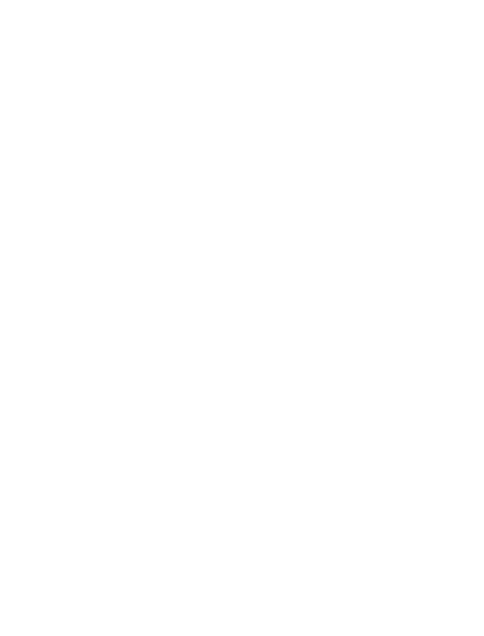

In [13]:
# Create game window
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

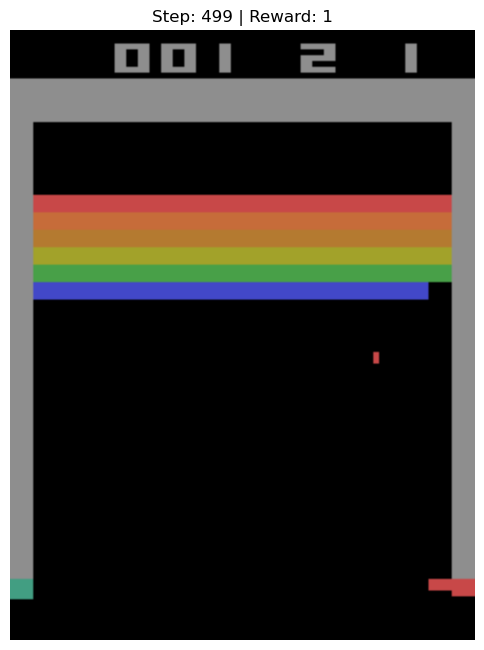

In [14]:
# Play game randomly
total_reward = 0

for step in range(500):
    # Take action
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    
    # Clear and update display
    clear_output(wait=True)
    ax.clear()
    ax.imshow(env.render())
    ax.set_title(f"Step: {step} | Reward: {total_reward:.0f}")
    ax.axis('off')
    
    display(fig)
    
    # Add delay to make it visible (adjust this value)
    time.sleep(0.03)  # 30ms delay = ~33 fps
    
    # Reset if game over
    if terminated or truncated:
        observation, info = env.reset()
        total_reward = 0

plt.close()
env.close()